# Project Deliverable 2: Regression Modeling and Performance Evaluation

**Student:** Xhon Pelushi  
**Course:** MSCS-634-B01 — Advanced Big Data and Data Mining  
**University:** University of the Cumberlands  
**Date:** November 2026

## Overview

This deliverable builds on the telecom churn dataset prepared in Deliverable 1. We develop regression models to predict **MonthlyCharges** based on customer attributes, applying feature engineering, multiple regression approaches, regularization, and cross-validation to evaluate model generalization.

---
## 1. Data Loading and Feature Engineering

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
%matplotlib inline

In [2]:
df = pd.read_csv('telecom_churn_data.csv')
print(f'Dataset shape: {df.shape}')
print(f'Columns: {list(df.columns)}')
df.head()

Dataset shape: (655, 11)
Columns: ['CustomerID', 'Gender', 'Age', 'Tenure', 'MonthlyCharges', 'TotalCharges', 'ContractType', 'InternetService', 'PaymentMethod', 'NumSupportTickets', 'Churned']


,CustomerID,Gender,Age,Tenure,MonthlyCharges,TotalCharges,ContractType,InternetService,PaymentMethod,NumSupportTickets,Churned
0,CID-0001,Male,79.0,48,61.42,2974.25,Two Year,Fiber Optic,Bank Transfer,3,0
1,CID-0002,Male,29.0,25,22.23,488.74,One Year,No Internet,Credit Card,0,0
2,CID-0003,Male,39.0,11,96.45,1055.55,Month-to-Month,Fiber Optic,Bank Transfer,1,1
3,CID-0004,Male,33.0,1,69.35,70.61,Month-to-Month,Fiber Optic,Mailed Check,3,1
4,CID-0005,Female,NaN,19,80.15,1527.20,Month-to-Month,Fiber Optic,Credit Card,2,1


In [3]:
print('Data types:')
print(df.dtypes)
print(f'\nMissing values:\n{df.isnull().sum()}')
df.describe()

Data types:
CustomerID               str
Gender                   str
Age                  float64
Tenure                 int64
MonthlyCharges       float64
TotalCharges         float64
ContractType             str
InternetService          str
PaymentMethod            str
NumSupportTickets      int64
Churned                int64
dtype: object

Missing values:
CustomerID            0
Gender                0
Age                  26
Tenure                0
MonthlyCharges       26
TotalCharges         26
ContractType          0
InternetService       0
PaymentMethod         0
NumSupportTickets     0
Churned               0
dtype: int64


,Age,Tenure,MonthlyCharges,TotalCharges,NumSupportTickets,Churned
count,629.000000,655.000000,629.000000,629.000000,655.000000,655.000000
mean,42.650238,21.712977,63.324356,1385.764738,1.477863,0.374046
std,14.007678,15.351939,27.240752,1225.258063,1.174024,0.484245
min,18.000000,1.000000,18.040000,-200.000000,0.000000,0.000000
25%,33.000000,8.500000,37.460000,440.760000,1.000000,0.000000
50%,42.000000,20.000000,66.050000,1074.500000,1.000000,0.000000
75%,52.000000,32.000000,86.760000,2021.170000,2.000000,1.000000
max,80.000000,72.000000,109.990000,6907.430000,6.000000,1.000000


### Feature Engineering

We create new features and encode categorical variables to prepare for regression modeling.

In [4]:
df_model = df.copy()

df_model['ChargesPerMonth_Tenure'] = df_model['TotalCharges'] / df_model['Tenure'].replace(0, 1)

df_model['HighSupportTickets'] = (df_model['NumSupportTickets'] >= 3).astype(int)

df_model['TenureGroup'] = pd.cut(df_model['Tenure'],
    bins=[0, 12, 24, 48, 100], labels=['0-12', '13-24', '25-48', '49+'])

df_model = pd.get_dummies(df_model,
    columns=['Gender', 'ContractType', 'InternetService', 'PaymentMethod', 'TenureGroup'],
    drop_first=True, dtype=int)

df_model = df_model.drop(columns=['CustomerID'])

df_model = df_model.fillna(0)

print(f'Features after engineering: {df_model.shape[1]} columns')
print(f'\nNew columns: {[c for c in df_model.columns if c not in df.columns]}')
print(f'Missing values remaining: {df_model.isnull().sum().sum()}')
df_model.head()

Features after engineering: 19 columns

New columns: ['ChargesPerMonth_Tenure', 'HighSupportTickets', 'Gender_Male', 'ContractType_One Year', 'ContractType_Two Year', 'InternetService_Fiber Optic', 'InternetService_No Internet', 'PaymentMethod_Credit Card', 'PaymentMethod_Electronic Check', 'PaymentMethod_Mailed Check', 'TenureGroup_13-24', 'TenureGroup_25-48', 'TenureGroup_49+']
Missing values remaining: 0


,Age,Tenure,MonthlyCharges,TotalCharges,NumSupportTickets,Churned,ChargesPerMonth_Tenure,HighSupportTickets,Gender_Male,ContractType_One Year,ContractType_Two Year,InternetService_Fiber Optic,InternetService_No Internet,PaymentMethod_Credit Card,PaymentMethod_Electronic Check,PaymentMethod_Mailed Check,TenureGroup_13-24,TenureGroup_25-48,TenureGroup_49+
0,79.0,48,61.42,2974.25,3,0,61.963542,1,1,0,1,1,0,0,0,0,0,1,0
1,29.0,25,22.23,488.74,0,0,19.549600,0,1,1,0,0,1,1,0,0,0,1,0
2,39.0,11,96.45,1055.55,1,1,95.959091,0,1,0,0,1,0,0,0,0,0,0,0
3,33.0,1,69.35,70.61,3,1,70.610000,1,1,0,0,1,0,0,0,1,0,0,0
4,0.0,19,80.15,1527.20,2,1,80.378947,0,0,0,0,1,0,1,0,0,1,0,0


In [5]:
target = 'MonthlyCharges'
features = [c for c in df_model.columns if c != target and c != 'Churned']

X = df_model[features]
y = df_model[target]

print(f'Feature matrix: {X.shape}')
print(f'Target variable: {target}')
print(f'Target stats: mean={y.mean():.2f}, std={y.std():.2f}, '
      f'min={y.min():.2f}, max={y.max():.2f}')

Feature matrix: (655, 17)
Target variable: MonthlyCharges
Target stats: mean=60.81, std=29.42, min=0.00, max=109.99


In [6]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42)

print(f'Training set: {X_train.shape[0]} samples')
print(f'Testing set:  {X_test.shape[0]} samples')

Training set: 524 samples
Testing set:  131 samples


In [7]:
def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f'{name}:')
    print(f'  MAE  = {mae:.4f}')
    print(f'  MSE  = {mse:.4f}')
    print(f'  RMSE = {rmse:.4f}')
    print(f'  R²   = {r2:.4f}')
    return {'Model': name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R²': r2}

results = []

---
## 2. Multiple Linear Regression

In [8]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

res = evaluate('Multiple Linear Regression', y_test, y_pred_lr)
results.append(res)

Multiple Linear Regression:
  MAE  = 10.8007
  MSE  = 249.3713
  RMSE = 15.7915
  R²   = 0.6994


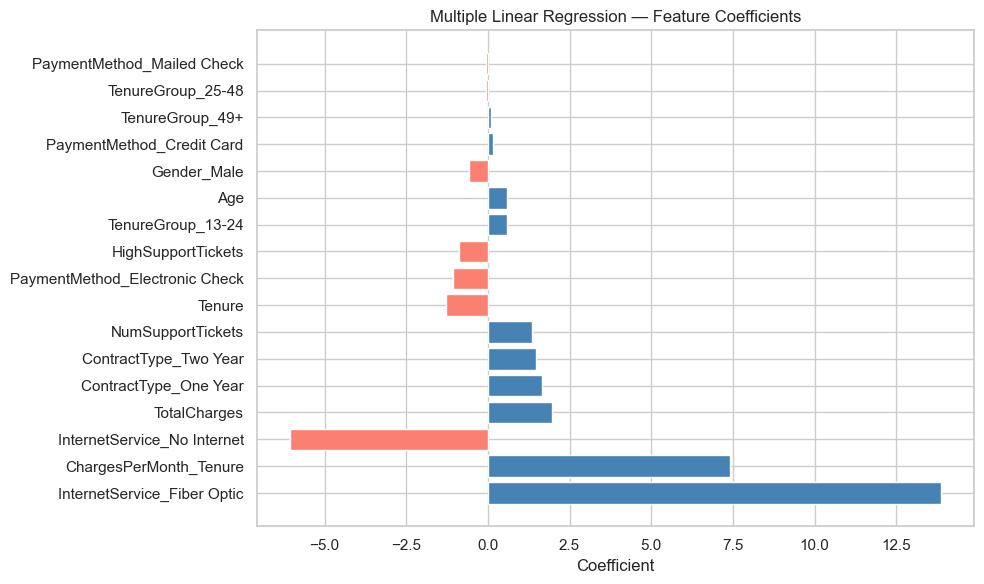

In [9]:
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

plt.figure(figsize=(10, 6))
colors = ['salmon' if c < 0 else 'steelblue' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
plt.xlabel('Coefficient')
plt.title('Multiple Linear Regression — Feature Coefficients')
plt.tight_layout()
plt.show()

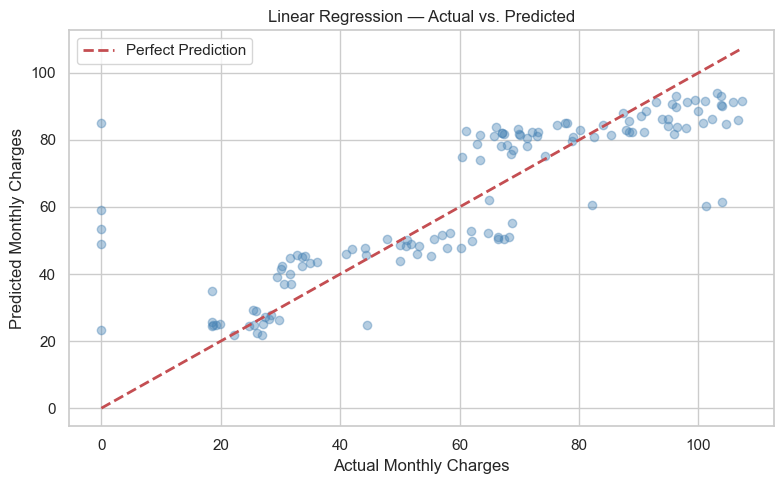

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_lr, alpha=0.4, color='steelblue')
mn, mx = y_test.min(), y_test.max()
plt.plot([mn, mx], [mn, mx], 'r--', linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Monthly Charges')
plt.ylabel('Predicted Monthly Charges')
plt.title('Linear Regression — Actual vs. Predicted')
plt.legend()
plt.tight_layout()
plt.show()

---
## 3. Ridge Regression (L2 Regularization)

In [11]:
alphas = [0.01, 0.1, 1.0, 10.0, 100.0]
ridge_scores = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train, y_train)
    y_pred = ridge.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    ridge_scores.append(r2)
    print(f'alpha = {alpha:6.2f}  |  R² = {r2:.4f}')

best_alpha = alphas[np.argmax(ridge_scores)]
print(f'\nBest alpha: {best_alpha}')

alpha =   0.01  |  R² = 0.6994
alpha =   0.10  |  R² = 0.6994
alpha =   1.00  |  R² = 0.6995
alpha =  10.00  |  R² = 0.7002
alpha = 100.00  |  R² = 0.6967

Best alpha: 10.0


In [12]:
ridge_best = Ridge(alpha=best_alpha)
ridge_best.fit(X_train, y_train)
y_pred_ridge = ridge_best.predict(X_test)

res = evaluate(f'Ridge Regression (alpha={best_alpha})', y_test, y_pred_ridge)
results.append(res)

Ridge Regression (alpha=10.0):
  MAE  = 10.7667
  MSE  = 248.6442
  RMSE = 15.7685
  R²   = 0.7002


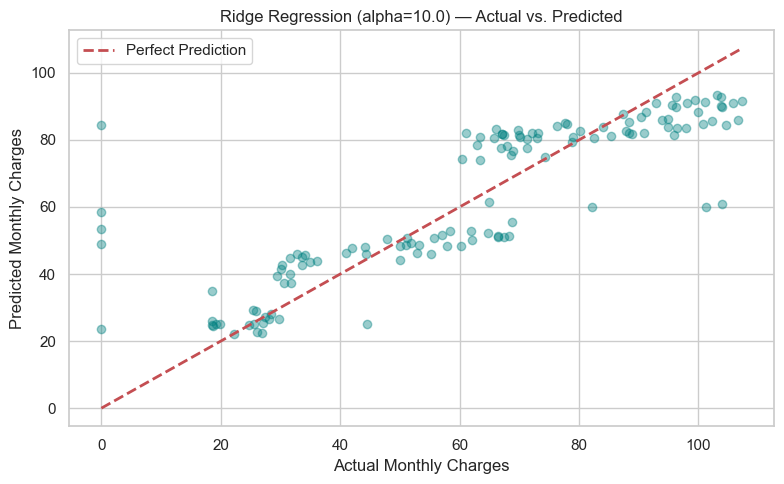

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_ridge, alpha=0.4, color='teal')
plt.plot([mn, mx], [mn, mx], 'r--', linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Monthly Charges')
plt.ylabel('Predicted Monthly Charges')
plt.title(f'Ridge Regression (alpha={best_alpha}) — Actual vs. Predicted')
plt.legend()
plt.tight_layout()
plt.show()

---
## 4. Lasso Regression (L1 Regularization)

In [14]:
lasso_scores = []

for alpha in alphas:
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train, y_train)
    y_pred = lasso.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    lasso_scores.append(r2)
    print(f'alpha = {alpha:6.2f}  |  R² = {r2:.4f}')

best_alpha_l = alphas[np.argmax(lasso_scores)]
print(f'\nBest alpha: {best_alpha_l}')

alpha =   0.01  |  R² = 0.6996
alpha =   0.10  |  R² = 0.6999
alpha =   1.00  |  R² = 0.6958
alpha =  10.00  |  R² = 0.5246
alpha = 100.00  |  R² = -0.0017

Best alpha: 0.1


In [15]:
lasso_best = Lasso(alpha=best_alpha_l, max_iter=10000)
lasso_best.fit(X_train, y_train)
y_pred_lasso = lasso_best.predict(X_test)

res = evaluate(f'Lasso Regression (alpha={best_alpha_l})', y_test, y_pred_lasso)
results.append(res)

print(f'\nFeatures zeroed by Lasso: {(lasso_best.coef_ == 0).sum()} of {len(X.columns)}')

Lasso Regression (alpha=0.1):
  MAE  = 10.7842
  MSE  = 248.9556
  RMSE = 15.7783
  R²   = 0.6999

Features zeroed by Lasso: 2 of 17


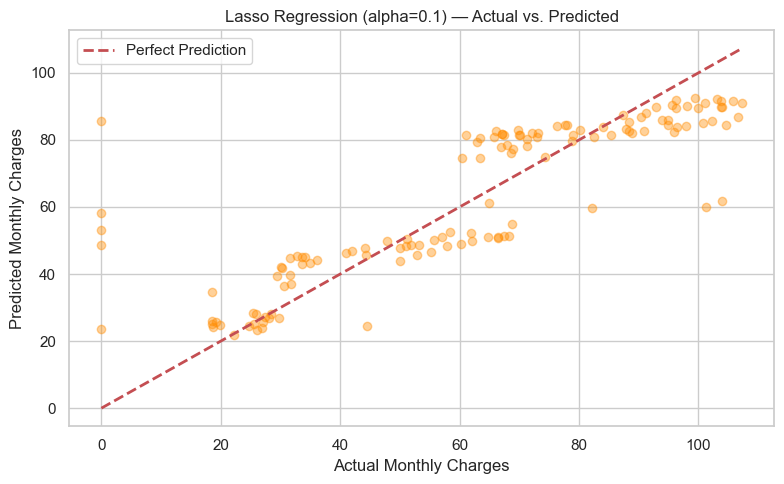

In [16]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_lasso, alpha=0.4, color='darkorange')
plt.plot([mn, mx], [mn, mx], 'r--', linewidth=2, label='Perfect Prediction')
plt.xlabel('Actual Monthly Charges')
plt.ylabel('Predicted Monthly Charges')
plt.title(f'Lasso Regression (alpha={best_alpha_l}) — Actual vs. Predicted')
plt.legend()
plt.tight_layout()
plt.show()

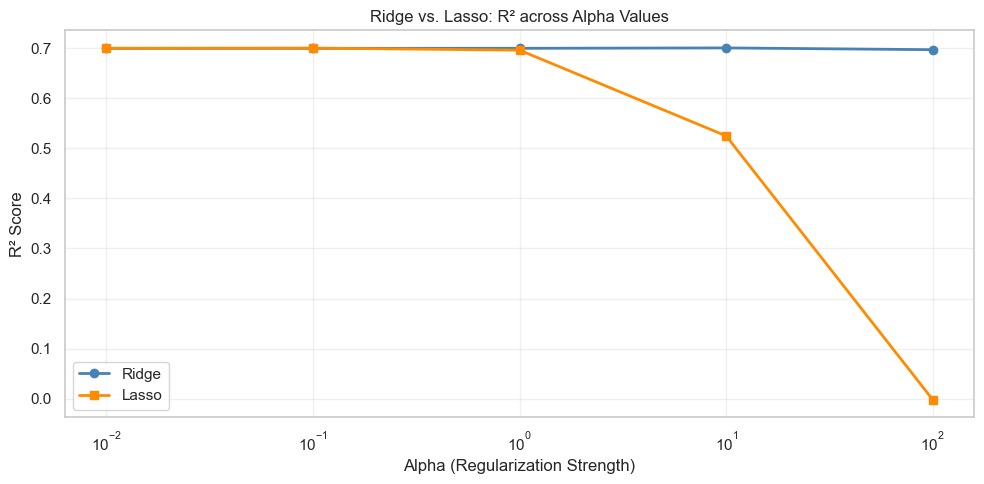

In [17]:
plt.figure(figsize=(10, 5))
plt.plot(alphas, ridge_scores, marker='o', linewidth=2, label='Ridge', color='steelblue')
plt.plot(alphas, lasso_scores, marker='s', linewidth=2, label='Lasso', color='darkorange')
plt.xscale('log')
plt.xlabel('Alpha (Regularization Strength)')
plt.ylabel('R² Score')
plt.title('Ridge vs. Lasso: R² across Alpha Values')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 5. Cross-Validation

In [18]:
models_cv = {
    'Linear Regression': LinearRegression(),
    f'Ridge (alpha={best_alpha})': Ridge(alpha=best_alpha),
    f'Lasso (alpha={best_alpha_l})': Lasso(alpha=best_alpha_l, max_iter=10000),
}

cv_results = []
print('5-Fold Cross-Validation R² Scores:\n')
for name, model in models_cv.items():
    scores = cross_val_score(model, X_scaled, y, cv=5, scoring='r2')
    print(f'{name:35s}  mean R² = {scores.mean():.4f} ± {scores.std():.4f}')
    cv_results.append({'Model': name, 'CV Mean R²': scores.mean(),
                       'CV Std': scores.std()})

5-Fold Cross-Validation R² Scores:

Linear Regression                    mean R² = 0.6758 ± 0.0359
Ridge (alpha=10.0)                   mean R² = 0.6779 ± 0.0349
Lasso (alpha=0.1)                    mean R² = 0.6784 ± 0.0352


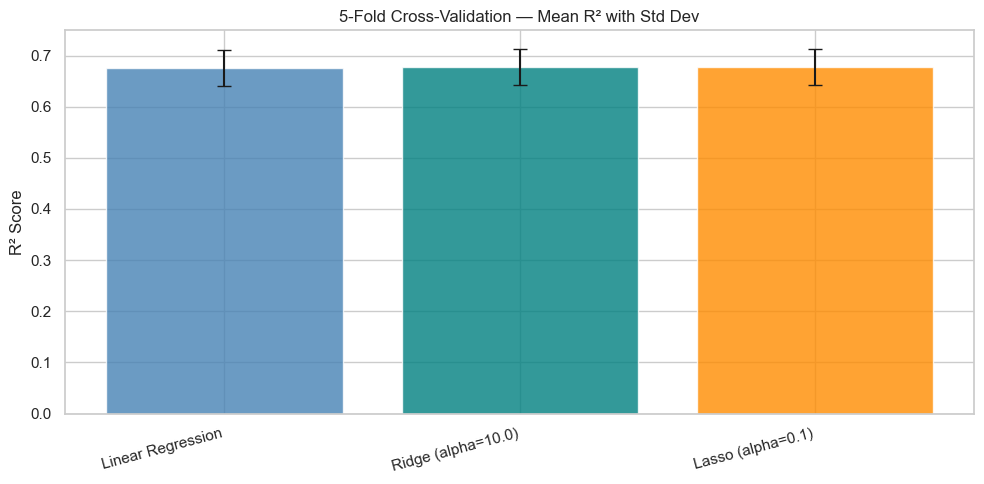

In [19]:
cv_df = pd.DataFrame(cv_results)

plt.figure(figsize=(10, 5))
x = np.arange(len(cv_df))
plt.bar(x, cv_df['CV Mean R²'], yerr=cv_df['CV Std'], capsize=5,
        color=['steelblue', 'teal', 'darkorange'], alpha=0.8)
plt.xticks(x, cv_df['Model'], rotation=15, ha='right')
plt.ylabel('R² Score')
plt.title('5-Fold Cross-Validation — Mean R² with Std Dev')
plt.tight_layout()
plt.show()

---
## 6. Model Comparison and Evaluation

In [20]:
comparison = pd.DataFrame(results)
print(comparison.to_string(index=False))

                        Model       MAE        MSE      RMSE       R²
   Multiple Linear Regression 10.800669 249.371315 15.791495 0.699359
Ridge Regression (alpha=10.0) 10.766685 248.644250 15.768457 0.700236
 Lasso Regression (alpha=0.1) 10.784158 248.955577 15.778326 0.699861


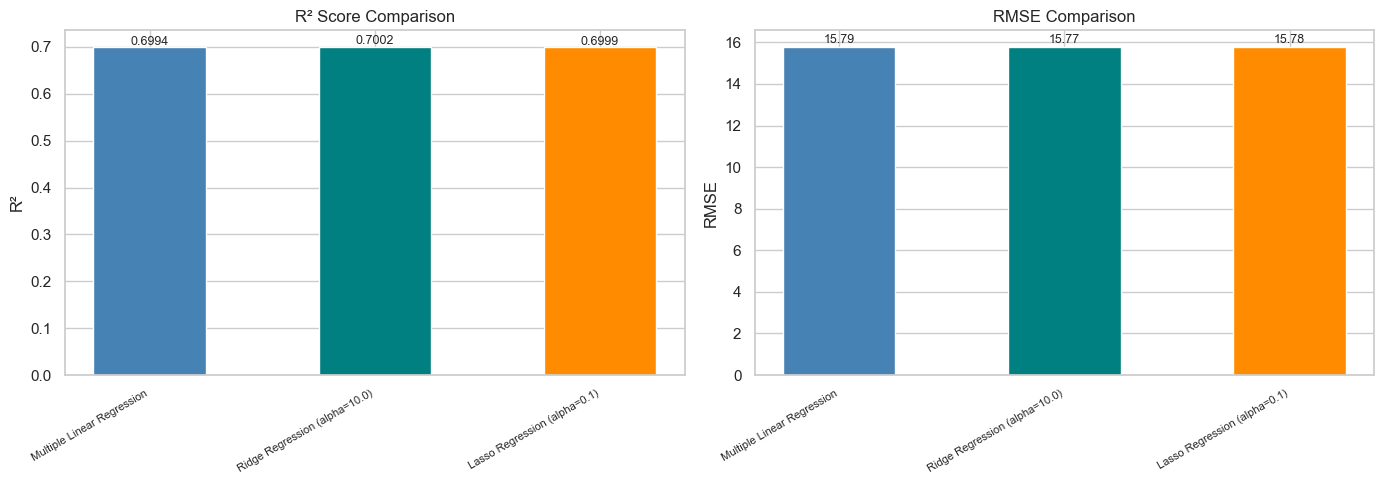

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = comparison['Model']
x = np.arange(len(models))
colors = ['steelblue', 'teal', 'darkorange']

axes[0].bar(x, comparison['R²'], color=colors, width=0.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, rotation=30, ha='right', fontsize=8)
axes[0].set_ylabel('R²')
axes[0].set_title('R² Score Comparison')
for i, v in enumerate(comparison['R²']):
    axes[0].text(i, v + 0.005, f'{v:.4f}', ha='center', fontsize=9)

axes[1].bar(x, comparison['RMSE'], color=colors, width=0.5)
axes[1].set_xticks(x)
axes[1].set_xticklabels(models, rotation=30, ha='right', fontsize=8)
axes[1].set_ylabel('RMSE')
axes[1].set_title('RMSE Comparison')
for i, v in enumerate(comparison['RMSE']):
    axes[1].text(i, v + 0.2, f'{v:.2f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### Residual Analysis

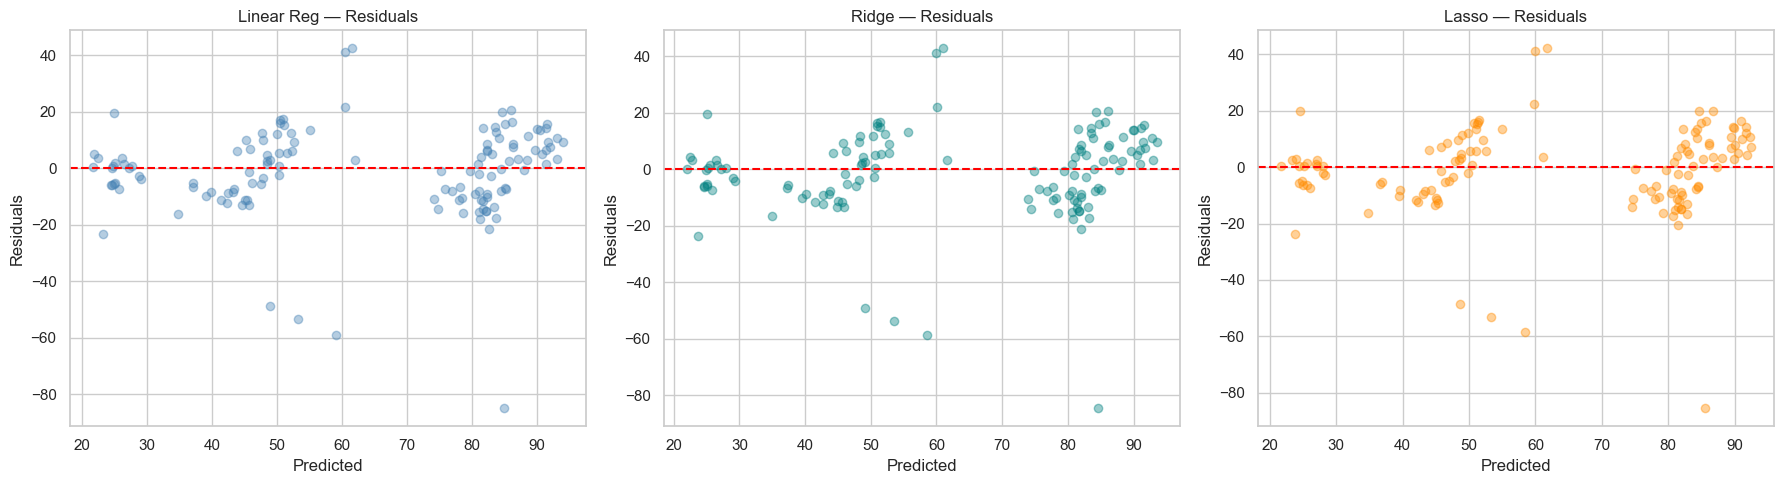

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred, color) in zip(axes,
    [('Linear Reg', y_pred_lr, 'steelblue'),
     ('Ridge', y_pred_ridge, 'teal'),
     ('Lasso', y_pred_lasso, 'darkorange')]):
    residuals = y_test.values - y_pred
    ax.scatter(y_pred, residuals, alpha=0.4, color=color)
    ax.axhline(y=0, color='red', linestyle='--')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Residuals')
    ax.set_title(f'{name} — Residuals')

plt.tight_layout()
plt.show()

---
## 7. Summary and Insights

### Model Performance

All three models (Multiple Linear Regression, Ridge, and Lasso) achieved similar performance on this dataset. The linear relationship between customer attributes and monthly charges is reasonably well captured by standard regression. Regularization with Ridge and Lasso did not provide major improvements because the feature space is modest (no severe multicollinearity or overfitting risk).

### Feature Engineering Impact

The engineered features — `ChargesPerMonth_Tenure`, `HighSupportTickets`, and tenure grouping — enriched the model's ability to capture relationships that the raw variables alone could not express. The charges-to-tenure ratio normalizes total charges by account duration, providing a more stable per-period signal.

### Insights About the Telecom Dataset

- **TotalCharges and Tenure** are the strongest predictors of MonthlyCharges, which is expected since total charges accumulate from monthly ones.
- **Contract type** significantly influences charges — month-to-month customers tend to have higher monthly rates than those on longer contracts.
- **Internet service type** also matters, with fiber optic customers paying more.
- Lasso's ability to zero out features reveals which attributes have minimal predictive value for monthly charges.

### Cross-Validation

Cross-validation confirms that the models generalize well, with consistent R² scores across folds. This indicates no severe overfitting in our regression approach.

### Next Steps (Deliverable 3)

Future work will explore classification models to predict the binary `Churned` target, apply clustering to segment customers, and build a complete predictive pipeline with evaluation on held-out data.